# Raport jakości danych — PJM Korpus

Analiza problematycznych próbek w zbiorze treningowym oraz generowanie przefiltrowanych splitów.

**Zawartość:**
1. Ładowanie danych
2. Struktura splitów
3. Problematyczne próbki
4. Analiza typów wideo
5. Analiza jakości tłumaczeń
6. Generowanie nowych splitów
7. Weryfikacja nowych splitów

## 1. Ładowanie danych

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

DATA_DIR = "./data"

analysis = pd.read_csv(f"{DATA_DIR}/selection_analysis.csv")
split_dfs = {
    split: pd.read_csv(f"{DATA_DIR}/split_{split}.csv").assign(split=split)
    for split in ["train", "val", "test"]
}
all_splits = pd.concat(split_dfs.values())

quality_cols = ["key", "mask_ratio", "word_count", "video_type", "special_case", "source_flag", "text"]
merged = all_splits.merge(analysis[quality_cols], on="key", how="left")

print(f"Wiersze w selection_analysis : {len(analysis):,}")
print(f"Wiersze w splitach (łącznie)  : {len(merged):,}")
print(f"Próbki poza splitami          : {len(analysis) - len(merged):,}")

Wiersze w selection_analysis : 39,817
Wiersze w splitach (łącznie)  : 33,897
Próbki poza splitami          : 5,920


## 2. Struktura splitów

In [17]:
print(f"{'Split':<8} {'Próbki':>8} {'Migający':>10}")
print("-" * 30)
for name, df in split_dfs.items():
    print(f"{name:<8} {len(df):>8,} {df['speaker_id'].nunique():>10}")
print("-" * 30)
print(f"{'TOTAL':<8} {len(merged):>8,} {merged['speaker_id'].nunique():>10}")

Split      Próbki   Migający
------------------------------
train      11,448         51
val        11,293         50
test       11,156         50
------------------------------
TOTAL      33,897        151


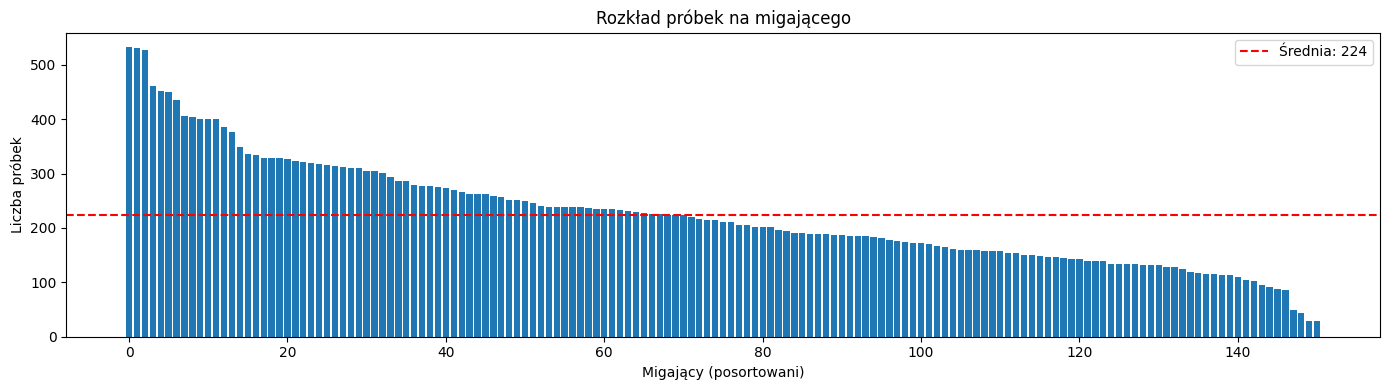

Min: 29  Max: 532  Std: 99.1


In [18]:
# Rozkład próbek na migającego
per_speaker = merged.groupby('speaker_id').size().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(range(len(per_speaker)), per_speaker.values)
ax.set_xlabel('Migający (posortowani)')
ax.set_ylabel('Liczba próbek')
ax.set_title('Rozkład próbek na migającego')
ax.axhline(per_speaker.mean(), color='red', linestyle='--', label=f'Średnia: {per_speaker.mean():.0f}')
ax.legend()
plt.tight_layout()
plt.show()
print(f"Min: {per_speaker.min()}  Max: {per_speaker.max()}  Std: {per_speaker.std():.1f}")

## 3. Problematyczne próbki

Identyfikujemy cztery kategorie problemów:
- **Krótkie teksty (word_count ≤ 2)**: jednowyrazowe odpowiedzi jak "Yes.", "Don't." — model nie może nauczyć się tłumaczyć z wideo
- **Niska jakość tłumaczenia (min_vocab_pct < 50)**: więcej niż połowa słów poza słownikiem referencyjnym
- **Próbki jednoręczne (one_hand)**: znaki produkowane jedną ręką — inna dystrybucja wizualna
- **Nieprawidłowe źródło (source_flag=invalid)**: błędnie oznaczone próbki

In [19]:
problems = pd.DataFrame({
    'split': ['train', 'val', 'test', 'TOTAL'],
})

for label, mask_fn in [
    ('word≤2',    lambda df: df['word_count'] <= 2),
    ('qual<50%',  lambda df: df['min_vocab_pct'] < 50),
    ('one_hand',  lambda df: df['special_case'] == 'one_hand'),
    ('invalid',   lambda df: df['source_flag'] == 'invalid'),
]:
    counts = []
    for split in ['train', 'val', 'test']:
        df = merged[merged['split'] == split]
        counts.append(mask_fn(df).sum())
    counts.append(sum(counts))
    problems[label] = counts

problems['total'] = [len(merged[merged['split']==s]) for s in ['train','val','test']] + [len(merged)]
display(problems)

,split,word≤2,qual<50%,one_hand,invalid,total
0,train,1256,340,0,0,11448
1,val,1201,395,230,0,11293
2,test,1146,309,0,0,11156
3,TOTAL,3603,1044,230,0,33897


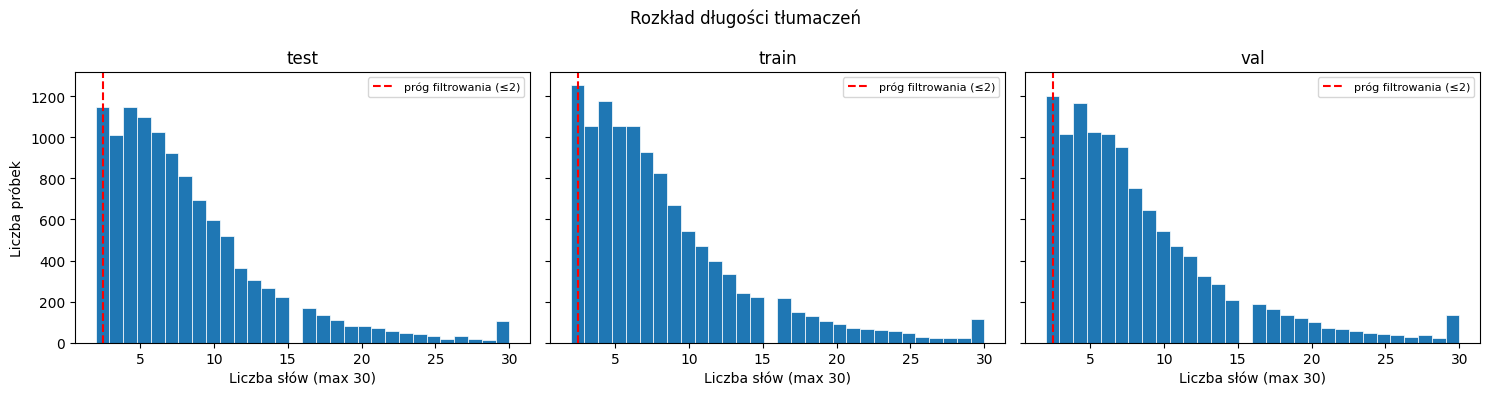

In [20]:
# Rozkład długości tekstów
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (split, df) in zip(axes, merged.groupby('split')):
    wc = df['word_count'].clip(upper=30)
    ax.hist(wc, bins=30, edgecolor='white', linewidth=0.5)
    ax.axvline(2.5, color='red', linestyle='--', label='próg filtrowania (≤2)')
    ax.set_title(split)
    ax.set_xlabel('Liczba słów (max 30)')
    ax.legend(fontsize=8)
axes[0].set_ylabel('Liczba próbek')
plt.suptitle('Rozkład długości tłumaczeń')
plt.tight_layout()
plt.show()

In [21]:
# Przykłady krótkich próbek
print("=== Przykłady próbek z word_count <= 2 ===")
short_examples = merged[merged['word_count'] <= 2][['key', 'text', 'word_count', 'min_vocab_pct', 'video_type', 'split']]
display(short_examples.sample(10, random_state=42).reset_index(drop=True))

=== Przykłady próbek z word_count <= 2 ===


,key,text,word_count,min_vocab_pct,video_type,split
0,317_004_R,"Okay, there.",2,79.94,dialog;obraz;komiks;Opowiedz mi komiks,test
1,583_110_R,"Well, after...",2,66.87,dialog;obraz;tekst;Spotkajmy się,train
2,530_014_M,Oh cool!,2,89.93,monolog;film;film aktorski;Brzdąc,val
3,413_079_R,Mom returned.,2,91.15,dialog;obraz;komiks;Opowiedz mi komiks,test
4,112_002_L,Saturday off.,2,74.71,dialog;obraz;tekst;Spotkajmy się,val
5,068_064_L,"Well, yes.",2,60.17,dialog;obraz;ilustracja;Co to za znak?,train
6,602_019_L,It doesn't.,2,36.59,dialog;obraz;komiks;Opowiedz mi komiks,train
7,014_001_M,Guess what?,2,88.56,monolog;obraz;komiks;Frog Story,test
8,716_032_L,"Security, protection.",2,98.31,dialog;obraz;ilustracja;Co to za znak?,train
9,147_003_R,At sixteen-thirty.,2,97.29,dialog;obraz;tekst;Spotkajmy się,train


## 4. Analiza typów wideo

Korpus składa się z 8 typów nagrań o różnej charakterystyce:
- **Co to za znak?** — dialogi pytające o izolowane znaki (najliczniejsza kategoria, ~35%)
- **Spotkajmy się** — dialogi o planowaniu spotkań
- **Opowiedz mi komiks** — opisy komiksów
- **Frog Story / Pear Stories / Brzdąc** — narracje monologowe
- **Canary Row / Alarm pożarowy** — opisy filmów

In [22]:
# Skrócone nazwy typów
TYPE_LABELS = {
    'dialog;obraz;ilustracja;Co to za znak?':     'Co to za znak?',
    'dialog;obraz;tekst;Spotkajmy się':           'Spotkajmy się',
    'dialog;obraz;komiks;Opowiedz mi komiks':     'Opowiedz mi komiks',
    'monolog;obraz;komiks;Frog Story':            'Frog Story',
    'monolog;film;film aktorski;Pear Stories':    'Pear Stories',
    'monolog;film;film aktorski;Brzdąc':          'Brzdąc',
    'monolog;film;animacja;Canary Row':           'Canary Row',
    'monolog;film;film w PJM;Alarm pożarowy':     'Alarm pożarowy',
}
merged['video_type_short'] = merged['video_type'].map(TYPE_LABELS)

vt_counts = merged.groupby(['video_type_short', 'split']).size().unstack(fill_value=0)
vt_counts['TOTAL'] = vt_counts.sum(axis=1)
display(vt_counts.sort_values('TOTAL', ascending=False))

split,test,train,val,TOTAL
video_type_short,,,,
Co to za znak?,2934,3801,3071,9806
Spotkajmy się,2435,1990,2530,6955
Opowiedz mi komiks,1209,1400,1363,3972
Frog Story,1084,1172,915,3171
Pear Stories,948,1089,1024,3061
Brzdąc,1179,871,826,2876
Canary Row,558,490,987,2035
Alarm pożarowy,809,635,577,2021


/tmp/ipykernel_71121/1086208676.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  short_pct = merged.groupby('video_type_short').apply(


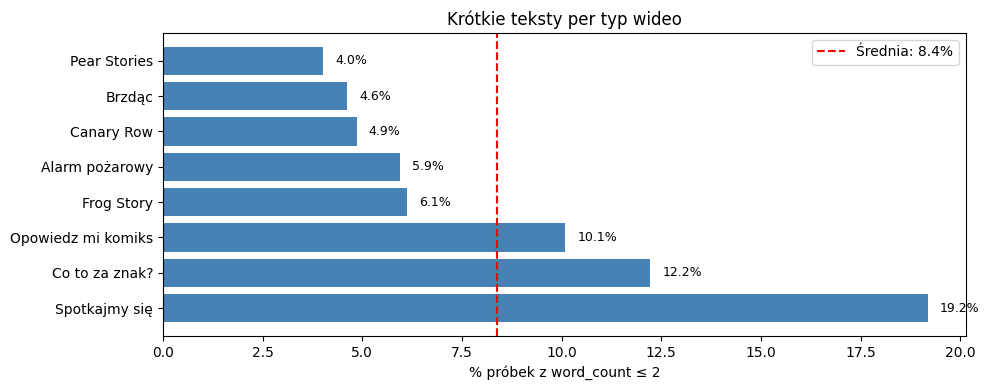

In [23]:
# Procent krótkich tekstów per typ wideo
short_pct = merged.groupby('video_type_short').apply(
    lambda df: (df['word_count'] <= 2).mean() * 100
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(short_pct.index, short_pct.values, color='steelblue')
ax.axvline(short_pct.mean(), color='red', linestyle='--', label=f'Średnia: {short_pct.mean():.1f}%')
ax.set_xlabel('% próbek z word_count ≤ 2')
ax.set_title('Krótkie teksty per typ wideo')
ax.legend()
for bar, val in zip(bars, short_pct.values):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2, f'{val:.1f}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

## 5. Analiza jakości tłumaczeń

`min_vocab_pct` — odsetek słów próbki który mieści się w słowniku referencyjnym. Niska wartość sygnalizuje błędne tłumaczenie lub bardzo rzadkie słownictwo.

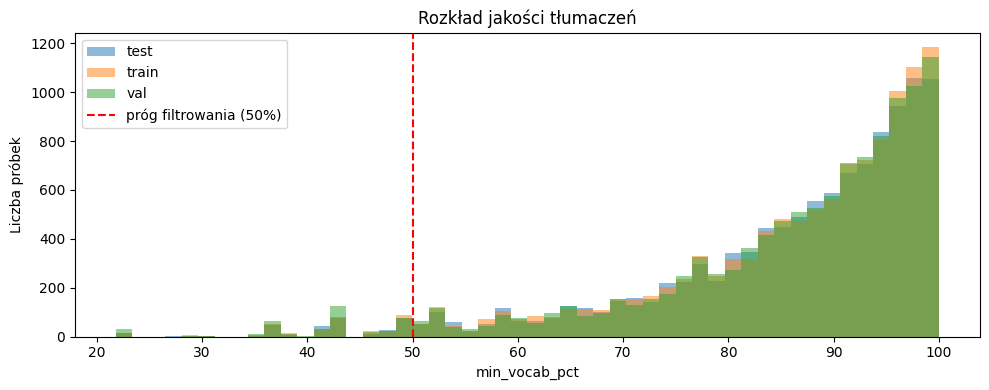

Próbki poniżej 50%: 1,044 (3.1%)
Próbki poniżej 70%: 4,283 (12.6%)


In [24]:
fig, ax = plt.subplots(figsize=(10, 4))
for split, df in merged.groupby('split'):
    ax.hist(df['min_vocab_pct'], bins=50, alpha=0.5, label=split)
ax.axvline(50, color='red', linestyle='--', label='próg filtrowania (50%)')
ax.set_xlabel('min_vocab_pct')
ax.set_ylabel('Liczba próbek')
ax.set_title('Rozkład jakości tłumaczeń')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Próbki poniżej 50%: {(merged['min_vocab_pct'] < 50).sum():,} ({100*(merged['min_vocab_pct'] < 50).mean():.1f}%)")
print(f"Próbki poniżej 70%: {(merged['min_vocab_pct'] < 70).sum():,} ({100*(merged['min_vocab_pct'] < 70).mean():.1f}%)")

In [25]:
# Przykłady złej jakości
print("=== Przykłady próbek z min_vocab_pct < 50% ===")
display(
    merged[merged['min_vocab_pct'] < 50][['key','text','word_count','min_vocab_pct','video_type_short']]
    .sample(10, random_state=42).reset_index(drop=True)
)

=== Przykłady próbek z min_vocab_pct < 50% ===


,key,text,word_count,min_vocab_pct,video_type_short
0,584_011_L,"There, see there.",3,48.53,Spotkajmy się
1,622_017_R,I was.,2,28.68,Co to za znak?
2,358_011_M,It goes.,2,42.12,Alarm pożarowy
3,214_067_L,You can.,2,43.56,Co to za znak?
4,644_022_M,He goes on.,3,42.12,Pear Stories
5,082_002_R,It doesn't.,2,36.59,Co to za znak?
6,595_034_R,I can.,2,43.56,Spotkajmy się
7,460_004_R,"Yes, yes.",2,49.81,Spotkajmy się
8,655_076_R,"You can't, no.",3,48.07,Spotkajmy się
9,426_030_R,"Yes, yes, yes.",3,49.81,Spotkajmy się


## 6. Generowanie nowych splitów

### Kryteria filtrowania
- `word_count >= 3` — usuwamy próbki z ≤2 słowami (backchannel, izolowane znaki)
- `min_vocab_pct >= 50` — usuwamy tłumaczenia niskiej jakości
- `source_flag != 'invalid'` — usuwamy błędnie oznaczone próbki

Splity migających pozostają niezmienione — filtrowanie usuwa tylko próbki, nie migających.

In [26]:
def filter_split(df: pd.DataFrame, min_words: int = 3, min_vocab: float = 50.0) -> pd.DataFrame:
    """Filtruje próbki według kryteriów jakości."""
    mask = (
        (df['word_count'] >= min_words) &
        (df['min_vocab_pct'] >= min_vocab) &
        (df['source_flag'] != 'invalid')
    )
    return df[mask]

# Pokaż wpływ filtrowania przed zapisem
print(f"{'Split':<8} {'Oryg.':>8} {'Po filtrze':>12} {'Usunięto':>10} {'%':>6}")
print("-" * 48)
for split in ['train', 'val', 'test']:
    df = merged[merged['split'] == split]
    filtered = filter_split(df)
    removed = len(df) - len(filtered)
    pct = 100 * removed / len(df)
    print(f"{split:<8} {len(df):>8,} {len(filtered):>12,} {removed:>10,} {pct:>5.1f}%")

total_orig = len(merged)
total_filt = len(filter_split(merged))
print("-" * 48)
print(f"{'TOTAL':<8} {total_orig:>8,} {total_filt:>12,} {total_orig-total_filt:>10,} {100*(total_orig-total_filt)/total_orig:>5.1f}%")

Split       Oryg.   Po filtrze   Usunięto      %
------------------------------------------------
train      11,448       10,063      1,385  12.1%
val        11,293        9,958      1,335  11.8%
test       11,156        9,911      1,245  11.2%
------------------------------------------------
TOTAL      33,897       29,932      3,965  11.7%


In [27]:
# Zapisz przefiltrowane splity
SAVE = True  # zmień na False żeby tylko podejrzeć bez zapisu

split_cols = ['key', 'speaker_id', 'interaction_type', 'sex', 'age', 'min_vocab_pct', 'decision', 'reason', 'flag']

for split in ['train', 'val', 'test']:
    orig_df = split_dfs[split]
    merged_split = merged[merged['split'] == split]
    filtered_keys = set(filter_split(merged_split)['key'])
    filtered_df = orig_df[orig_df['key'].isin(filtered_keys)]
    
    out_path = f"{DATA_DIR}/split_{split}_filtered.csv"
    if SAVE:
        filtered_df.to_csv(out_path, index=False)
        print(f"Zapisano {out_path}: {len(filtered_df):,} próbek")
    else:
        print(f"[DRY RUN] {out_path}: {len(filtered_df):,} próbek")

Zapisano ./data/split_train_filtered.csv: 10,063 próbek
Zapisano ./data/split_val_filtered.csv: 9,958 próbek
Zapisano ./data/split_test_filtered.csv: 9,911 próbek


## 7. Weryfikacja nowych splitów

In [28]:
new_splits = {
    split: pd.read_csv(f"{DATA_DIR}/split_{split}_filtered.csv")
    for split in ['train', 'val', 'test']
}
new_merged = pd.concat(new_splits.values()).merge(analysis[quality_cols], on='key', how='left')

print("=== Weryfikacja — problematyczne próbki po filtrze ===")
print(f"{'Split':<8} {'Próbki':>8} {'Migający':>10} {'word≤2':>8} {'qual<50':>8} {'one_hand':>10}")
print("-" * 58)
for split in ['train', 'val', 'test']:
    df = new_merged[new_merged['split'] == split]
    print(f"{split:<8} {len(df):>8,} {df['speaker_id'].nunique():>10} "
          f"{(df['word_count']<=2).sum():>8} "
          f"{(df['min_vocab_pct']<50).sum():>8} "
          f"{(df['special_case']=='one_hand').sum():>10}")

print()
print("=== Pokrycie typów wideo po filtrze ===")
vt_new = new_merged.groupby(['video_type', 'split']).size().unstack(fill_value=0)
vt_new.index = vt_new.index.map(TYPE_LABELS)
vt_new['TOTAL'] = vt_new.sum(axis=1)
display(vt_new.sort_values('TOTAL', ascending=False))

=== Weryfikacja — problematyczne próbki po filtrze ===
Split      Próbki   Migający   word≤2  qual<50   one_hand
----------------------------------------------------------
train      10,063         51        0        0          0
val         9,958         50        0        0        196
test        9,911         50        0        0          0

=== Pokrycie typów wideo po filtrze ===


split,test,train,val,TOTAL
video_type,,,,
Co to za znak?,2534,3285,2674,8493
Spotkajmy się,2008,1520,2000,5528
Opowiedz mi komiks,1071,1243,1231,3545
Frog Story,1015,1087,836,2938
Pear Stories,905,1048,966,2919
Brzdąc,1099,827,787,2713
Canary Row,525,460,919,1904
Alarm pożarowy,754,593,545,1892


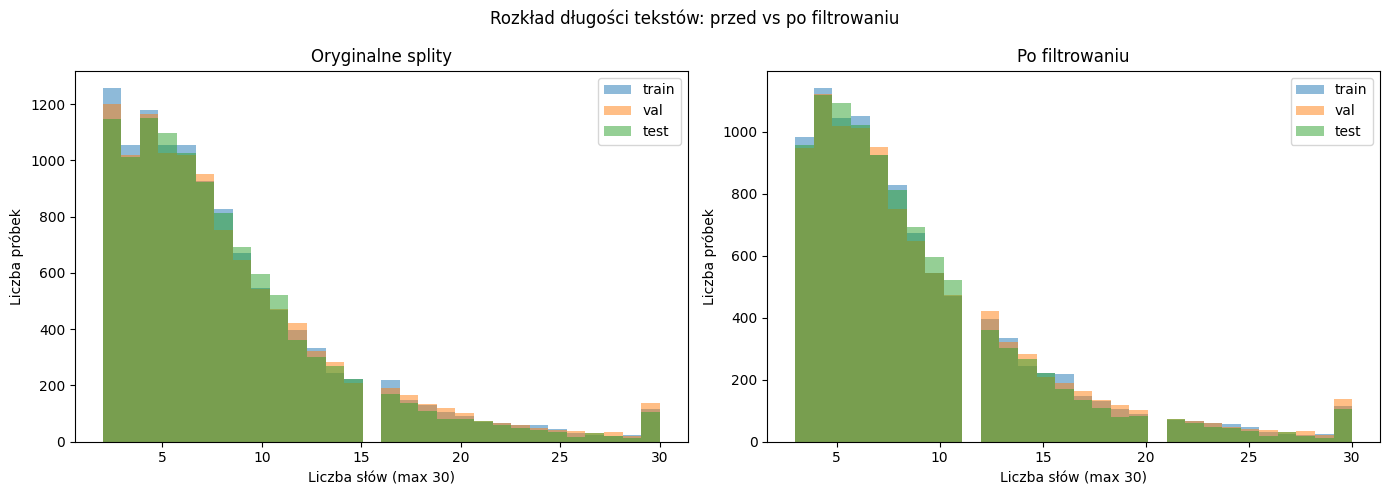

In [29]:
# Porównanie rozkładu długości tekstów: przed vs po
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (label, data) in zip(axes, [('Oryginalne splity', merged), ('Po filtrowaniu', new_merged)]):
    for split in ['train', 'val', 'test']:
        wc = data[data['split']==split]['word_count'].clip(upper=30)
        ax.hist(wc, bins=30, alpha=0.5, label=split)
    ax.set_title(label)
    ax.set_xlabel('Liczba słów (max 30)')
    ax.set_ylabel('Liczba próbek')
    ax.legend()

plt.suptitle('Rozkład długości tekstów: przed vs po filtrowaniu')
plt.tight_layout()
plt.show()

In [30]:
# Sprawdzenie czy splity nie mają przecieków migających
train_speakers = set(new_splits['train']['speaker_id'])
val_speakers   = set(new_splits['val']['speaker_id'])
test_speakers  = set(new_splits['test']['speaker_id'])

tv_overlap = train_speakers & val_speakers
tt_overlap = train_speakers & test_speakers
vt_overlap = val_speakers & test_speakers

print("=== Sprawdzenie przecieków migających ===")
print(f"Train ∩ Val  : {len(tv_overlap)} migających")
print(f"Train ∩ Test : {len(tt_overlap)} migających")
print(f"Val   ∩ Test : {len(vt_overlap)} migających")
if tv_overlap or tt_overlap or vt_overlap:
    print("UWAGA: znaleziono przecieki migających!")
else:
    print("OK: brak przecieków — splity są rozdzielone po migających")

=== Sprawdzenie przecieków migających ===
Train ∩ Val  : 0 migających
Train ∩ Test : 0 migających
Val   ∩ Test : 0 migających
OK: brak przecieków — splity są rozdzielone po migających
